# Stage 3 – MRI Preprocessing and Stratified Data Splitting

**Research project:** An Unsupervised Graph-Based Framework for Adversarial Attack Detection and Severity Estimation in Deep Learning-Based Alzheimer’s MRI Classification.

## Stage 2 validation findings used to design this notebook
- 6,400 images were listed and all 6,400 were resolved and readable.
- All images are 128 × 128 pixels, grayscale (`L` mode), JPEG.
- No exact duplicate files were detected using SHA-256.
- The apparent 3,200 folder-label mismatches were only the `Non-Demented` versus `Non_Demented` punctuation difference; the labels and paths agree after normalizing hyphens and underscores.
- Class counts: Non-Demented 3,200; Very Mild Demented 2,240; Mild Demented 896; Moderate Demented 64.

## Decisions in this stage
- Preserve the already validated 128 × 128 grayscale images; no unnecessary resizing or colour conversion is needed.
- Convert pixel values to floating point in the range [0, 1] when creating model inputs.
- Use a reproducible, stratified 70% / 15% / 15% image-level train/validation/test split with random seed 42.
- Save split manifests and processed arrays. Store images as `uint8` in the archive to keep file size manageable; convert to `[0,1]` when loading for a model.

**Important limitation:** the dataset metadata does not provide patient identifiers. This is an image-level split, not a verified patient-level split. Near-duplicate visual images have not been ruled out by the exact SHA-256 check.

## 1. Upload the original dataset ZIP and Stage 1 CSV

Run this cell and select:
1. The original Alzheimer preprocessed dataset ZIP.
2. Your `alzheimer_dataset_index.csv` from Stage 1.

Do not upload the Stage 2 report ZIP in place of the original dataset ZIP. The report contains audit information, not the MRI image files.

In [6]:
from google.colab import files
uploaded = files.upload()
print("Uploaded:", list(uploaded.keys()))

Saving alzheimer_dataset_index.csv to alzheimer_dataset_index.csv
Uploaded: ['alzheimer_dataset_index.csv']


## 2. Imports and reproducibility settings

In [8]:
import os, glob, zipfile, random, json, shutil
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

NumPy: 2.4.6
Pandas: 2.2.3


## 3. Identify the uploaded ZIP and CSV

In [10]:
import os
import glob

# Fallback check: Look directly inside the /content/ directory for matching files
all_content_files = [os.path.basename(f) for f in glob.glob("/content/*")]

zip_files = [f for f in all_content_files if f.lower().endswith(".zip")]
csv_files = [f for f in all_content_files if f.lower().endswith(".csv") and "alzheimer_dataset_index" in f.lower()]

# Fallback in case of custom naming
if not csv_files:
    csv_files = [f for f in all_content_files if f.lower().endswith(".csv")]

print("ZIP files detected:", zip_files)
print("CSV files detected:", csv_files)

if not zip_files:
    raise FileNotFoundError("Please upload the original dataset ZIP via the upload cell or sidebar.")
if not csv_files:
    raise FileNotFoundError("Please upload the Stage 1 alzheimer_dataset_index.csv via the upload cell or sidebar.")

ZIP_PATH = "/content/" + zip_files[0]
CSV_PATH = "/content/" + csv_files[0]

print("Using ZIP:", ZIP_PATH)
print("Using CSV:", CSV_PATH)

ZIP files detected: ['Alzheimer (Preprocessed Data) (1).zip']
CSV files detected: ['alzheimer_dataset_index.csv']
Using ZIP: /content/Alzheimer (Preprocessed Data) (1).zip
Using CSV: /content/alzheimer_dataset_index.csv


## 4. Extract the original dataset

In [11]:
EXTRACT_DIR = "/content/alzheimer_mri_stage3_source"
os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    zf.extractall(EXTRACT_DIR)

print("Extraction completed.")
print("JPG files found:", len(glob.glob(EXTRACT_DIR + "/**/*.jpg", recursive=True)))

Extraction completed.
JPG files found: 6400


## 5. Load the Stage 1 index and resolve image paths

In [12]:
index_df = pd.read_csv(CSV_PATH)
if not {"path", "label"}.issubset(index_df.columns):
    raise ValueError("The Stage 1 CSV must contain 'path' and 'label' columns.")

def resolve_by_class_and_filename(row):
    # Use the class label plus filename to locate the correct file in the extracted ZIP.
    label = str(row["label"]).strip()
    filename = os.path.basename(str(row["path"]))
    class_folder = label.replace("-", "_").replace(" ", "_")
    candidates = glob.glob(EXTRACT_DIR + "/**/" + class_folder + "/" + filename, recursive=True)
    if len(candidates) == 1:
        return candidates[0]
    # Case-insensitive class-folder fallback; only accept a unique filename match.
    candidates = glob.glob(EXTRACT_DIR + "/**/" + filename, recursive=True)
    if len(candidates) == 1:
        return candidates[0]
    return None

index_df["resolved_path"] = index_df.apply(resolve_by_class_and_filename, axis=1)
print("CSV rows:", len(index_df))
print("Resolved:", int(index_df["resolved_path"].notna().sum()))
print("Unresolved:", int(index_df["resolved_path"].isna().sum()))

if index_df["resolved_path"].isna().any():
    display(index_df[index_df["resolved_path"].isna()].head(20))
    raise RuntimeError("Some CSV entries could not be matched to source images. Stop and inspect the paths.")
if index_df["resolved_path"].duplicated().any():
    raise RuntimeError("A source image was matched to more than one CSV row. Stop and inspect the index.")

CSV rows: 6400
Resolved: 6400
Unresolved: 0


## 6. Confirm class counts and normalise label spelling

In [13]:
# Canonical class order, preserving the terminology used in the dataset.
CLASS_NAMES = [
    "Mild Demented",
    "Moderate Demented",
    "Non-Demented",
    "Very Mild Demented"
]

index_df["label"] = index_df["label"].astype(str).str.strip()
unexpected = sorted(set(index_df["label"]) - set(CLASS_NAMES))
if unexpected:
    raise ValueError(f"Unexpected class labels found: {unexpected}")

class_counts = index_df["label"].value_counts().reindex(CLASS_NAMES, fill_value=0)
display(class_counts.rename("images").to_frame())

expected_counts = {
    "Mild Demented": 896,
    "Moderate Demented": 64,
    "Non-Demented": 3200,
    "Very Mild Demented": 2240
}
for cls, expected in expected_counts.items():
    actual = int(class_counts[cls])
    if actual != expected:
        print(f"NOTE: {cls}: expected audit count {expected}, current CSV count {actual}")

,images
label,
Mild Demented,896
Moderate Demented,64
Non-Demented,3200
Very Mild Demented,2240


## 7. Verify images and prepare the pixel arrays

In [14]:
images_uint8 = []
valid_rows = []
image_properties = []

for row in index_df.itertuples(index=False):
    path = row.resolved_path
    try:
        with Image.open(path) as im:
            im.load()
            # Stage 2 found all images already 128x128 grayscale.
            if im.size != (128, 128):
                raise ValueError(f"Unexpected dimensions {im.size}")
            if im.mode != "L":
                raise ValueError(f"Unexpected image mode {im.mode}")
            arr = np.asarray(im, dtype=np.uint8)
            if arr.shape != (128, 128):
                raise ValueError(f"Unexpected array shape {arr.shape}")
        images_uint8.append(arr)
        valid_rows.append({"source_path": path, "label": row.label})
        image_properties.append((arr.min(), arr.max()))
    except Exception as e:
        raise RuntimeError(f"Image validation failed for {path}: {e}")

X_uint8 = np.stack(images_uint8, axis=0)
metadata = pd.DataFrame(valid_rows)

print("Image array shape:", X_uint8.shape)
print("Image data type:", X_uint8.dtype)
print("Pixel minimum:", int(X_uint8.min()))
print("Pixel maximum:", int(X_uint8.max()))
print("Metadata rows:", len(metadata))

Image array shape: (6400, 128, 128)
Image data type: uint8
Pixel minimum: 0
Pixel maximum: 255
Metadata rows: 6400


## 8. Encode class labels

In [15]:
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(metadata["label"])

class_mapping = {
    str(class_name): int(label_encoder.transform([class_name])[0])
    for class_name in label_encoder.classes_
}
print("Class-to-integer mapping:")
print(json.dumps(class_mapping, indent=2))

Class-to-integer mapping:
{
  "Mild Demented": 0,
  "Moderate Demented": 1,
  "Non-Demented": 2,
  "Very Mild Demented": 3
}


## 9. Create stratified 70% / 15% / 15% split

In [16]:
# First reserve 30% for validation + test.
all_indices = np.arange(len(metadata))
train_idx, temp_idx = train_test_split(
    all_indices,
    test_size=0.30,
    random_state=SEED,
    stratify=y
)

# Split the remaining 30% equally into 15% validation and 15% test.
y_temp = y[temp_idx]
val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

split_name = np.empty(len(metadata), dtype=object)
split_name[train_idx] = "train"
split_name[val_idx] = "validation"
split_name[test_idx] = "test"

metadata["label_id"] = y
metadata["split"] = split_name

print("Split sizes:")
print(metadata["split"].value_counts())
print("\nClass distribution by split:")
split_counts = pd.crosstab(metadata["label"], metadata["split"])
display(split_counts.reindex(CLASS_NAMES))

Split sizes:
split
train         4480
test           960
validation     960
Name: count, dtype: int64

Class distribution by split:


split,test,train,validation
label,,,
Mild Demented,135,627,134
Moderate Demented,9,45,10
Non-Demented,480,2240,480
Very Mild Demented,336,1568,336


## 10. Verify no overlap between splits

In [17]:
train_paths = set(metadata.loc[metadata.split == "train", "source_path"])
val_paths = set(metadata.loc[metadata.split == "validation", "source_path"])
test_paths = set(metadata.loc[metadata.split == "test", "source_path"])

assert train_paths.isdisjoint(val_paths)
assert train_paths.isdisjoint(test_paths)
assert val_paths.isdisjoint(test_paths)
assert len(train_paths | val_paths | test_paths) == len(metadata)

print("PASS: no source file path is shared between splits.")
print("Train:", len(train_paths), "Validation:", len(val_paths), "Test:", len(test_paths))

PASS: no source file path is shared between splits.
Train: 4480 Validation: 960 Test: 960


## 11. Convert images to [0, 1] and inspect a sample

Float array shape: (6400, 128, 128)
Float dtype: float32
Scaled pixel range: 0.0 to 1.0


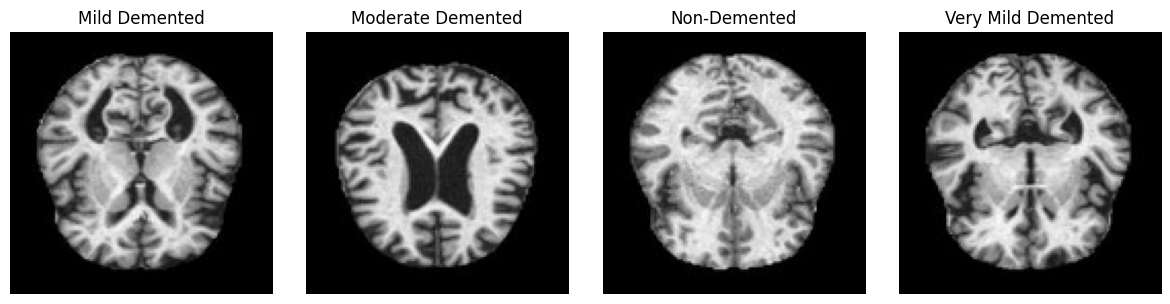

In [18]:
# Keep the canonical archive as uint8; this float array demonstrates the model input scaling.
X_float = X_uint8.astype(np.float32) / 255.0
print("Float array shape:", X_float.shape)
print("Float dtype:", X_float.dtype)
print("Scaled pixel range:", float(X_float.min()), "to", float(X_float.max()))

import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for ax, cls in zip(axes, CLASS_NAMES):
    idx = metadata.index[metadata.label == cls][0]
    ax.imshow(X_float[idx], cmap="gray", vmin=0, vmax=1)
    ax.set_title(cls)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 12. Save reproducible outputs

In [19]:
OUT_DIR = "/content/stage3_preprocessed"
os.makedirs(OUT_DIR, exist_ok=True)

# Save lossless uint8 image arrays to reduce storage; scale to float32 when loading.
np.savez_compressed(
    os.path.join(OUT_DIR, "alzheimer_images_uint8.npz"),
    X=X_uint8,
    y=y.astype(np.int64),
    class_names=np.array(label_encoder.classes_, dtype=str)
)

metadata.to_csv(os.path.join(OUT_DIR, "split_manifest.csv"), index=False)
split_counts.to_csv(os.path.join(OUT_DIR, "class_distribution_by_split.csv"))

config = {
    "random_seed": SEED,
    "image_dimensions": [128, 128],
    "image_mode": "grayscale",
    "stored_image_dtype": "uint8",
    "model_input_scaling": "float32 / 255.0, range [0,1]",
    "split_proportions": {"train": 0.70, "validation": 0.15, "test": 0.15},
    "split_method": "two-step stratified train_test_split",
    "split_unit": "image-level",
    "patient_identifiers_available": False,
    "class_mapping": class_mapping,
    "total_images": int(len(metadata)),
    "split_counts": metadata["split"].value_counts().to_dict(),
    "class_counts": metadata["label"].value_counts().to_dict()
}
with open(os.path.join(OUT_DIR, "preprocessing_config.json"), "w") as f:
    json.dump(config, f, indent=2)

print("Saved outputs:")
for f in sorted(os.listdir(OUT_DIR)):
    print(f, os.path.getsize(os.path.join(OUT_DIR, f)), "bytes")

Saved outputs:
alzheimer_images_uint8.npz 59977882 bytes
class_distribution_by_split.csv 138 bytes
preprocessing_config.json 781 bytes
split_manifest.csv 771838 bytes


## 13. Download the Stage 3 output package

In [20]:
from google.colab import files
shutil.make_archive("/content/Stage3_Preprocessing_Outputs", "zip", OUT_DIR)
files.download("/content/Stage3_Preprocessing_Outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 14. What to send back

Upload `Stage3_Preprocessing_Outputs.zip` here. I will check:
- Actual train/validation/test sizes.
- Per-class counts in each split.
- Class-to-integer mapping.
- Saved preprocessing configuration.

Do not begin CNN training yet. Stage 4 will use this exact split and preprocessing configuration so that later experiments remain consistent.

### Important scientific notes
- This is an image-level split because patient identifiers are not provided in the dataset metadata.
- The absence of exact SHA-256 duplicates does not rule out visually similar or near-duplicate scans.
- The Moderate Demented test subset is small; report its metrics with caution.
- No data augmentation has been applied to validation or test images. If augmentation is later needed, it will be applied only to training data.